## EN3160 Assignment 03: Neural Networks
### Bandara W.D.A.C. - 230082G
Github Repo : [https://github.com/Achintha-Bandara/CVNN.git](https://github.com/Achintha-Bandara/CVNN.git)

#### Q1. Single-Layer Network vs. Multi-Layer Network

Using device: cuda
GPU: NVIDIA GeForce MX550
Epoch 1/20, Loss: 0.976996
Epoch 2/20, Loss: 0.949854
Epoch 3/20, Loss: 0.936094
Epoch 4/20, Loss: 0.927540
Epoch 5/20, Loss: 0.921602
Epoch 6/20, Loss: 0.917199
Epoch 7/20, Loss: 0.913785
Epoch 8/20, Loss: 0.911056
Epoch 9/20, Loss: 0.908828
Epoch 10/20, Loss: 0.906975
Epoch 11/20, Loss: 0.905415
Epoch 12/20, Loss: 0.904087
Epoch 13/20, Loss: 0.902948
Epoch 14/20, Loss: 0.901965
Epoch 15/20, Loss: 0.901111
Epoch 16/20, Loss: 0.900366
Epoch 17/20, Loss: 0.899713
Epoch 18/20, Loss: 0.899140
Epoch 19/20, Loss: 0.898634
Epoch 20/20, Loss: 0.898188


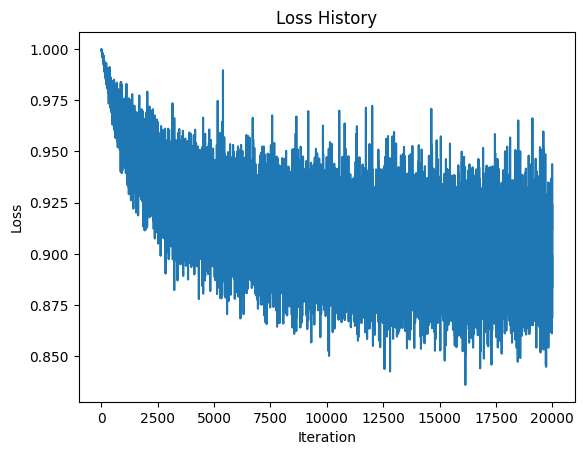

Training accuracy: 32.22%
Test accuracy: 32.45%


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 0. Select Compute Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases on the selected device
w = torch.randn(Din, K, device=device) * std
b = torch.zeros(K, device=device)

# Hyperparameters
iterations = 20
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        Ntr = inputs.shape[0]

        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss calculation (Mean Squared Error with regularization)
        loss = (
            (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2)
            + reg * torch.sum(w ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        with torch.no_grad():
            w -= lr * dw
            b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader):.6f}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Using device: cuda
GPU: NVIDIA GeForce MX550
Epoch 1/10, Loss: 1.787216
Epoch 2/10, Loss: 1.615576
Epoch 3/10, Loss: 1.524926
Epoch 4/10, Loss: 1.455107
Epoch 5/10, Loss: 1.393695
Epoch 6/10, Loss: 1.339421
Epoch 7/10, Loss: 1.296118
Epoch 8/10, Loss: 1.250795
Epoch 9/10, Loss: 1.212518
Epoch 10/10, Loss: 1.177318


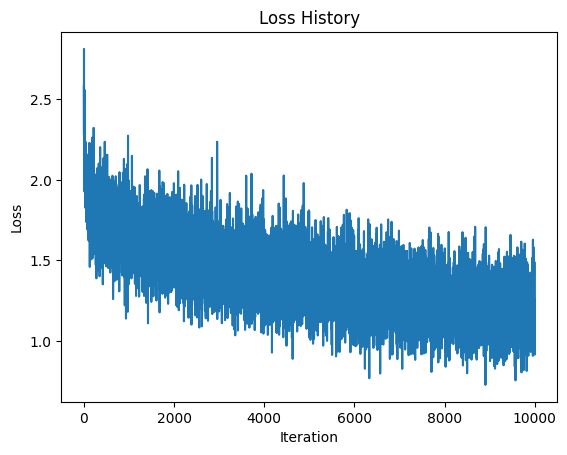

Training accuracy: 61.32%
Test accuracy: 48.86%


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 0. Select Compute Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

# 2. Define Network Parameters
Din = 3 * 32 * 32
H = 100
K = 10

# Initialize weights and biases
# Xavier initialization
w1 = torch.randn(Din, H, device=device) * (2.0 / (Din + H))**0.5
b1 = torch.zeros(H, device=device)
w2 = torch.randn(H, K, device=device) * (2.0 / (H + K))**0.5
b2 = torch.zeros(K, device=device)

# Hyperparameters
iterations = 10
lr = 0.4
lr_decay = 0.9
loss_history = []

criterion = nn.CrossEntropyLoss()

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        hidden = torch.sigmoid(x_train.mm(w1) + b1)
        y_pred = hidden.mm(w2) + b2

        # Cross-entropy loss
        loss = criterion(y_pred, labels)

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1)
        dy_pred[torch.arange(Ntr, device=device), labels] -= 1
        dy_pred /= Ntr

        dw2 = hidden.t().mm(dy_pred)
        db2 = dy_pred.sum(dim=0)

        dhidden = dy_pred.mm(w2.t())
        dz1 = dhidden * hidden * (1 - hidden)

        dw1 = x_train.t().mm(dz1)
        db1 = dz1.sum(dim=0)

        # Parameter update
        with torch.no_grad():
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

    print(
        f"Epoch {t + 1}/{iterations}, "
        f"Loss: {running_loss / len(trainloader):.6f}"
    )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for inputs, labels in trainloader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        x_train = inputs.view(inputs.shape[0], -1)

        hidden = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = hidden.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        x_test = inputs.view(inputs.shape[0], -1)

        hidden = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = hidden.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

The original code uses a single linear layer to classify images, whereas the improved code introduces a hidden layer with 100 neurons and sigmoid activation, allowing the network to learn nonlinear relationships. It also replaces Mean Squared Error (MSE) with cross-entropy loss, which is more suitable for multi-class classification. Xavier initialization is used to initialize the weights more appropriately, and the network is trained for 10 epochs instead of 20. The improved code calculates gradients for both layers and updates their weights and biases using backpropagation. Also the learning rate is increased, so that the model converges faster and achieves better results within a less number of iterations.

#### Q2 - CNN

##### LeNet-5

Using device: cuda
GPU: NVIDIA GeForce MX550
Epoch 1/10 | Train Loss: 0.3860 | Test Loss: 0.1015 | Train Accuracy: 89.05% | Test Accuracy: 96.97%
Epoch 2/10 | Train Loss: 0.0903 | Test Loss: 0.0622 | Train Accuracy: 97.29% | Test Accuracy: 98.05%
Epoch 3/10 | Train Loss: 0.0606 | Test Loss: 0.0554 | Train Accuracy: 98.17% | Test Accuracy: 98.25%
Epoch 4/10 | Train Loss: 0.0484 | Test Loss: 0.0448 | Train Accuracy: 98.53% | Test Accuracy: 98.51%
Epoch 5/10 | Train Loss: 0.0404 | Test Loss: 0.0428 | Train Accuracy: 98.78% | Test Accuracy: 98.56%
Epoch 6/10 | Train Loss: 0.0351 | Test Loss: 0.0371 | Train Accuracy: 98.95% | Test Accuracy: 98.80%
Epoch 7/10 | Train Loss: 0.0306 | Test Loss: 0.0335 | Train Accuracy: 99.07% | Test Accuracy: 98.88%
Epoch 8/10 | Train Loss: 0.0259 | Test Loss: 0.0350 | Train Accuracy: 99.20% | Test Accuracy: 98.79%
Epoch 9/10 | Train Loss: 0.0231 | Test Loss: 0.0324 | Train Accuracy: 99.29% | Test Accuracy: 98.92%
Epoch 10/10 | Train Loss: 0.0201 | Test Loss: 

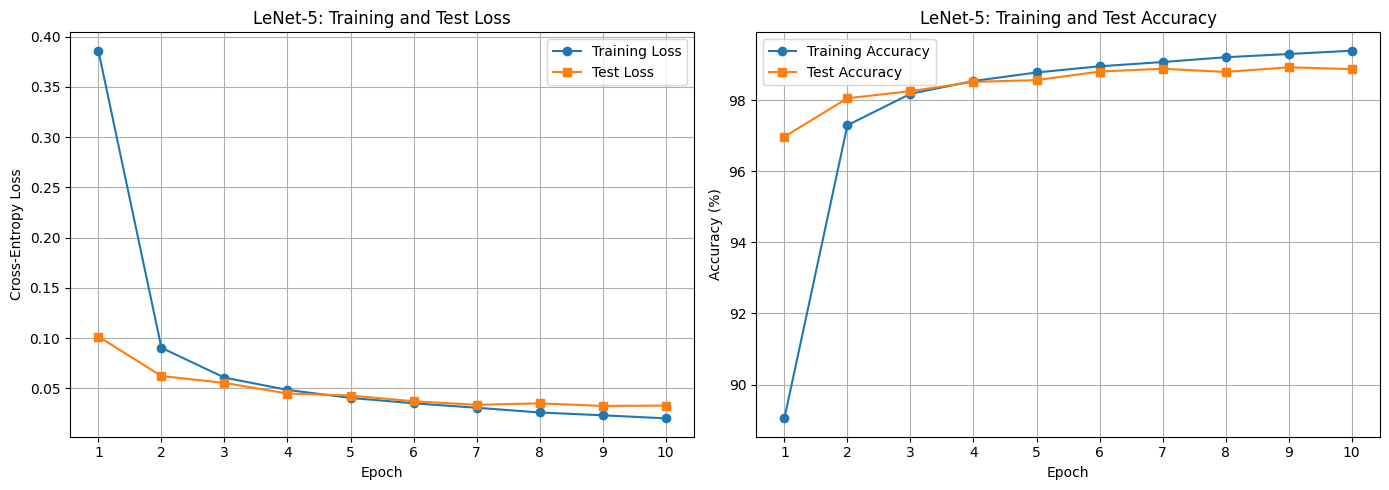


Final training accuracy: 99.39%
Final test accuracy: 98.87%


In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 1. Load MNIST Dataset
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

trainset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)

testset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

# 2. Define LeNet-5 Network
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.tanh(self.conv1(x))
        x = self.pool1(x)
        x = self.tanh(self.conv2(x))
        x = self.pool2(x)
        x = x.view(x.size(0), -1)
        x = self.tanh(self.fc1(x))
        x = self.tanh(self.fc2(x))
        x = self.fc3(x)
        return x

lenet_model = LeNet5().to(device)

# 3. Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(lenet_model.parameters(), lr=0.01, momentum=0.9)

epochs = 10

# Store metrics for plotting
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

# 4. Training and Evaluation Loop
def evaluate(loader):
    lenet_model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = lenet_model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            predicted = torch.argmax(outputs, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy

for epoch in range(epochs):
    lenet_model.train()
    running_loss = 0.0
    total_train = 0
    correct_train = 0

    for inputs, labels in trainloader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        # Forward pass
        outputs = lenet_model(inputs)
        loss = criterion(outputs, labels)
        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        predicted = torch.argmax(outputs, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    # Training metrics
    train_loss = running_loss / total_train
    train_acc = 100.0 * correct_train / total_train

    # Test metrics
    test_loss, test_acc = evaluate(testloader)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

# 5. Plot Training and Test Loss
epoch_numbers = range(1, epochs + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Training and Test Loss
ax[0].plot(epoch_numbers, train_losses, marker='o', label='Training Loss')
ax[0].plot(epoch_numbers, test_losses, marker='s', label='Test Loss')
ax[0].set_title('LeNet-5: Training and Test Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Cross-Entropy Loss')
ax[0].set_xticks(epoch_numbers)
ax[0].legend()
ax[0].grid(True)

# Training and Test Accuracy
ax[1].plot(epoch_numbers, train_accuracies, marker='o', label='Training Accuracy')
ax[1].plot(epoch_numbers, test_accuracies, marker='s', label='Test Accuracy')
ax[1].set_title('LeNet-5: Training and Test Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy (%)')
ax[1].set_xticks(epoch_numbers)
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

# 7. Report Final Accuracies
print(f"\nFinal training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final test accuracy: {test_accuracies[-1]:.2f}%")

##### Modern CNN

Using device: cuda
GPU: NVIDIA GeForce MX550
Epoch 1/10 | Train Loss: 0.2050 | Test Loss: 0.0506 | Train Accuracy: 93.68% | Test Accuracy: 98.46%
Epoch 2/10 | Train Loss: 0.0858 | Test Loss: 0.0319 | Train Accuracy: 97.41% | Test Accuracy: 99.06%
Epoch 3/10 | Train Loss: 0.0616 | Test Loss: 0.0409 | Train Accuracy: 98.18% | Test Accuracy: 98.59%
Epoch 4/10 | Train Loss: 0.0509 | Test Loss: 0.0275 | Train Accuracy: 98.59% | Test Accuracy: 99.13%
Epoch 5/10 | Train Loss: 0.0434 | Test Loss: 0.0237 | Train Accuracy: 98.69% | Test Accuracy: 99.26%
Epoch 6/10 | Train Loss: 0.0376 | Test Loss: 0.0344 | Train Accuracy: 98.87% | Test Accuracy: 98.86%
Epoch 7/10 | Train Loss: 0.0351 | Test Loss: 0.0254 | Train Accuracy: 98.92% | Test Accuracy: 99.24%
Epoch 8/10 | Train Loss: 0.0300 | Test Loss: 0.0281 | Train Accuracy: 99.08% | Test Accuracy: 99.18%
Epoch 9/10 | Train Loss: 0.0288 | Test Loss: 0.0211 | Train Accuracy: 99.11% | Test Accuracy: 99.36%
Epoch 10/10 | Train Loss: 0.0236 | Test Loss: 

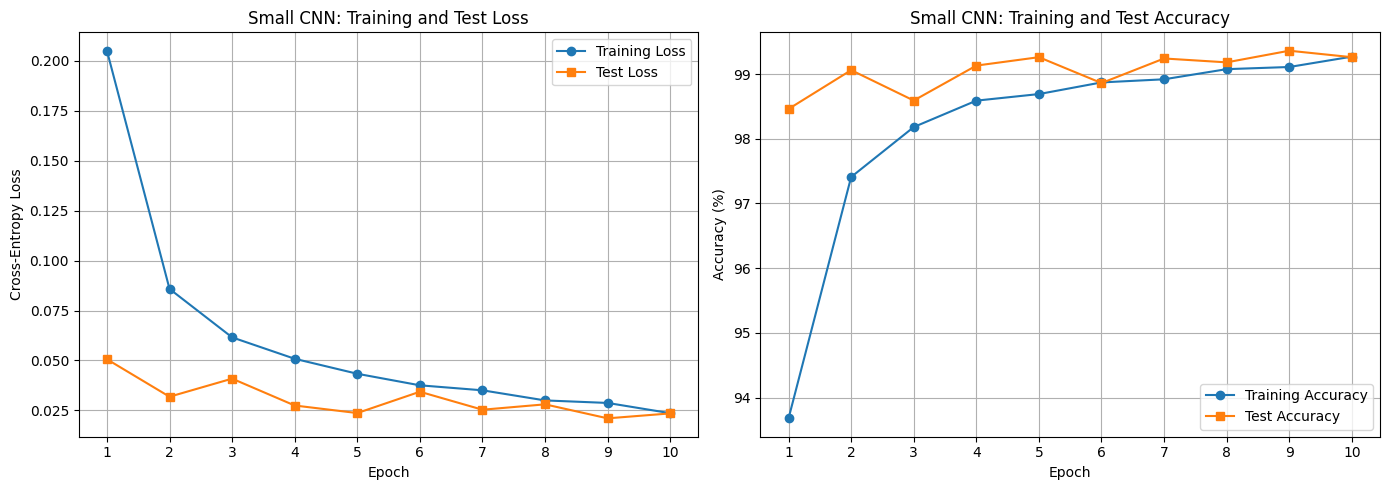


Final training accuracy: 99.27%
Final test accuracy: 99.26%


In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 1. Load MNIST Dataset
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

trainset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)

testset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

# 2. Define Modern 3-Layer CNN
class SmallCNN(nn.Module):
    def __init__(self):
        super(SmallCNN, self).__init__()
        self.features = nn.Sequential(
            # Convolutional layer 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Convolutional layer 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Convolutional layer 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

cnn_model = SmallCNN().to(device)

# 3. Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    cnn_model.parameters(),
    lr=0.01,
    momentum=0.9
)

epochs = 10

train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

# 4. Evaluation Function
def evaluate(loader):
    cnn_model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = cnn_model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return total_loss / total, 100.0 * correct / total

# 5. Training Loop
for epoch in range(epochs):
    cnn_model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in trainloader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        # Forward pass
        outputs = cnn_model(inputs)
        loss = criterion(outputs, labels)
        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        predicted = outputs.argmax(dim=1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / total_train
    train_acc = 100.0 * correct_train / total_train
    test_loss, test_acc = evaluate(testloader)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

# 6. Plot Loss and Accuracy in One Figure
epoch_numbers = range(1, epochs + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epoch_numbers, train_losses, marker='o', label='Training Loss')
ax[0].plot(epoch_numbers, test_losses, marker='s', label='Test Loss')
ax[0].set_title('Small CNN: Training and Test Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Cross-Entropy Loss')
ax[0].set_xticks(list(epoch_numbers))
ax[0].legend()
ax[0].grid(True)

ax[1].plot(epoch_numbers, train_accuracies, marker='o', label='Training Accuracy')
ax[1].plot(epoch_numbers, test_accuracies, marker='s', label='Test Accuracy')
ax[1].set_title('Small CNN: Training and Test Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy (%)')
ax[1].set_xticks(list(epoch_numbers))
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

# 7. Final Accuracies
print(f"\nFinal training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final test accuracy: {test_accuracies[-1]:.2f}%")

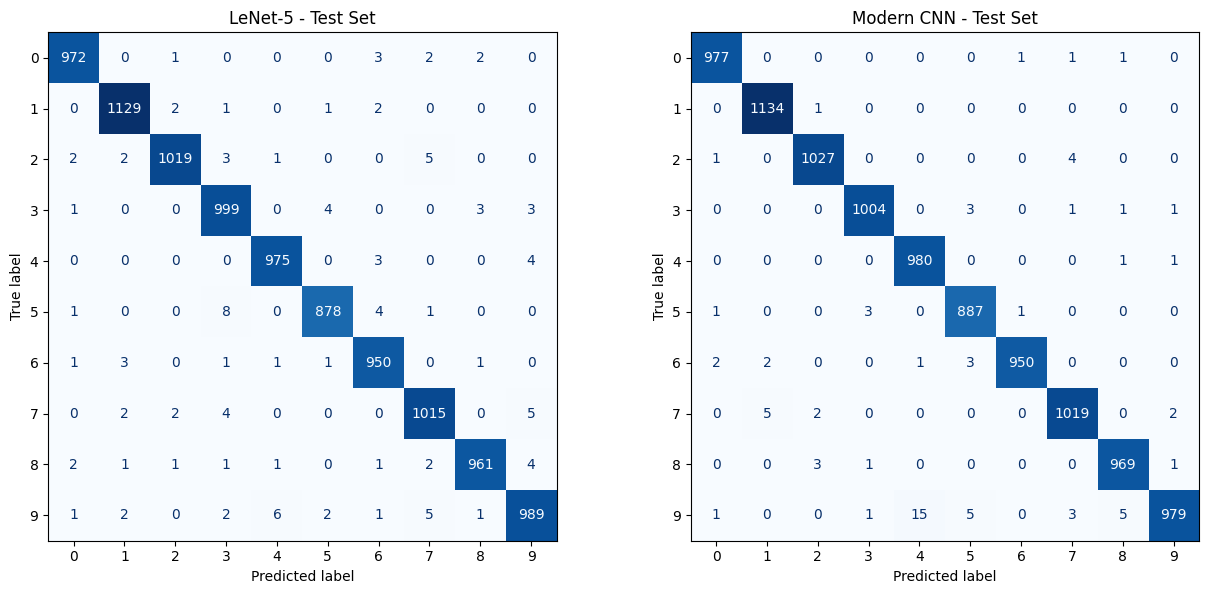

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

models = [("LeNet-5", lenet_model), ("Modern CNN", cnn_model)]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, (name, model) in zip(axes, models):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)
            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{name} - Test Set")

plt.tight_layout()
plt.show()